# OGLE data access: from EWS page to normalized observations

This notebook is an executable inspection of the public OGLE-IV Early Warning System adapter. It shows the raw web table, the normalized target table, optional sky/magnitude filters, and the per-event `phot.dat` observations.

In [1]:
from io import StringIO
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import requests
from target_selection import data_source


SEASON = 2026
CACHE_DIR = Path('outputs/cache/ogle_photometry')
EWS = data_source.ogle
EWS_URL = EWS.describe()['catalog_url']
EWS.describe(), EWS_URL

({'name': 'ogle',
  'kind': 'survey',
  'features': ['targets', 'parameters', 'epochs', 'photometry'],
  'catalog_url': 'https://ogle.astrouw.edu.pl/ogle4/ews/ews.html',
  'photometry': 'OGLE EWS public I-band phot.dat files',
  'quality_note': 'EWS parameters and photometry are preliminary/provisional.'},
 'https://ogle.astrouw.edu.pl/ogle4/ews/ews.html')

## 1. Inspect the public EWS page

The adapter downloads the HTML page, decodes it as Latin-1, and reads its event table with `pandas.read_html`. This cell shows the raw response and the columns before normalization.

In [2]:
response = requests.get(EWS_URL, timeout=60)
response.raise_for_status()
raw_html = response.content.decode('latin-1')
raw_tables = pd.read_html(StringIO(raw_html))
raw_events = raw_tables[0]
print(f'HTTP status: {response.status_code}')
print(f'HTML bytes: {len(response.content):,}')
print(f'Tables found: {len(raw_tables)}')
print('Raw columns:')
display(raw_events.head())

HTTP status: 200
HTML bytes: 278,055
Tables found: 1
Raw columns:


,Unnamed: 0,Event,Field,Star No,RA (J2000),Dec (J2000),Tmax (HJD),Tmax (UT),tau,Umin,Amax,Dmag,fbl,Ibl,I0
0,NaN,2026-BLG-0001,BLG499.21,4189,17:19:55.45,-30:16:43.4,2461065.134,2026-01-24.63,42.838,0.183,5.534,1.858,1.000,17.971,17.971
1,NaN,2026-BLG-0002,BLG500.01,92092,17:54:08.86,-29:01:25.1,2461093.940,2026-02-22.44,453.842,0.014,72.729,2.246,0.096,19.433,21.974
2,NaN,2026-BLG-0003,BLG500.04,30440,17:52:14.90,-29:00:12.6,2461183.814,2026-05-23.31,157.964,0.563,1.980,0.742,1.000,17.718,17.718
3,NaN,2026-BLG-0004,BLG500.05,113286,17:50:57.48,-29:01:04.8,2461090.285,2026-02-18.79,29.318,0.677,1.719,0.588,1.000,17.646,17.646
4,NaN,2026-BLG-0005,BLG500.19,31825,17:53:36.31,-28:24:33.7,2461105.413,2026-03-05.91,24.755,0.266,3.856,0.912,0.461,17.584,18.424


## 2. Load normalized OGLE targets

The adapter converts sexagesimal coordinates to degrees and maps the preliminary microlensing model parameters `Tmax`, `tau` and `Umin` to `t0_hjd`, `tE_days` and `u0`. `Tmax` is the fitted time of maximum magnification, `tau` is the fitted event timescale, and `Umin` is the minimum lens-source separation in Einstein-radius units. These are preliminary EWS parameters and can change as the event develops. The original OGLE columns and event URLs remain available.

In [3]:
events = EWS.load_targets(season=SEASON)
print(f'Loaded targets: {len(events):,}')
display(events[['target_id', 'ra_deg', 'dec_deg', 't0_hjd', 'tE_days', 'u0', 'category', 'photometry_url']].head())

Loaded targets: 937


,target_id,ra_deg,dec_deg,t0_hjd,tE_days,u0,category,photometry_url
0,2026-BLG-0001,259.981042,-30.278722,2461065.134,42.838,0.183,ews_candidate,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
1,2026-BLG-0002,268.536917,-29.023639,2461093.940,453.842,0.014,ews_candidate,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
2,2026-BLG-0003,268.062083,-29.003500,2461183.814,157.964,0.563,ews_candidate,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
3,2026-BLG-0004,267.739500,-29.018000,2461090.285,29.318,0.677,ews_candidate,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
4,2026-BLG-0005,268.401292,-28.409361,2461105.413,24.755,0.266,ews_candidate,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...


In [4]:
# Proof of concept: links are built from the event identifier, then checked against the event page.
import inspect
from target_selection.sources.ogle import _event_paths
from urllib.parse import urljoin
import re

event_id = str(events.iloc[0]['target_id'])
constructed_links = _event_paths(event_id)
print('Implementation of _event_paths:')
print(inspect.getsource(_event_paths))
event_response = requests.get(constructed_links['event_url'], timeout=60)
event_response.raise_for_status()
hrefs = [urljoin(constructed_links['event_url'], href) for href in re.findall(r'href="([^"]+)', event_response.text, flags=re.IGNORECASE)]
print('Event:', event_id)
print('Links constructed by the adapter:')
display(pd.Series(constructed_links))
print('Links actually present in the event HTML:')
display(pd.Series(hrefs))

Event: 2026-BLG-0001
Links constructed by the adapter:


event_url            https://ogle.astrouw.edu.pl/ogle4/ews/blg-0001...
photometry_url       https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
archive_url          https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
finding_chart_url    https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
dtype: object

Links actually present in the event HTML:


0                https://ogle.astrouw.edu.pl/fig/oo.png
1     https://ogle.astrouw.edu.pl/ogle4/ews/blg-0002...
2     https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
3        https://ogle.astrouw.edu.pl/ogle4/ews/ews.html
4     https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
5     https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
6     https://ogle.astrouw.edu.pl/ogle4/ews/blg-0002...
7     https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
8     https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
9     https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...
10    https://ogle.astrouw.edu.pl/ogle4/ews/blg-0002...
dtype: object

## 3. Filter by magnitude and sky region

`magnitude_range` uses the OGLE EWS I-band baseline magnitude (`Ibl`). `ra_range` and `dec_range` use degrees. A right-ascension interval that crosses 0 degrees is supported.

In [13]:
filtered_events = EWS.load_targets(
    season=SEASON,
    magnitude_range=(None, 17.0),
    ra_range=(250.0, 280.0),
    dec_range=(-25.0, -20.0),
)
print(f'Filtered targets: {len(filtered_events):,}')
display(filtered_events[['target_id', 'ra_deg', 'dec_deg', 'magnitude_baseline_I']].head())

Filtered targets: 33


,target_id,ra_deg,dec_deg,magnitude_baseline_I
47,2026-BLG-0048,275.227167,-23.659222,16.192
62,2026-BLG-0063,273.343833,-23.573667,15.809
91,2026-BLG-0092,265.577333,-21.392417,15.731
92,2026-BLG-0093,265.730333,-23.077306,16.263
95,2026-BLG-0096,266.695458,-24.061861,15.880


In [ ]:
# Proof of concept: the public method is equivalent to these explicit masks.
base = EWS.load_targets(season=SEASON)
magnitude = pd.to_numeric(base['magnitude_baseline_I'], errors='coerce')
mask = magnitude.le(17.0)
mask &= base['ra_deg'].between(250.0, 280.0)
mask &= base['dec_deg'].between(-25.0, -20.0)
manual_filtered = base.loc[mask].copy()
print(f'Before filters: {len(base):,}')
print(f'After explicit masks: {len(manual_filtered):,}')
print(f'After EWS.load_targets: {len(filtered_events):,}')
assert set(manual_filtered['target_id']) == set(filtered_events['target_id'])

The same magnitude filter can be expressed through the generic provider filter interface:

In [14]:
bright_events = EWS.load_targets(
    season=SEASON,
    filters={'magnitude': {'maximum': 17.0}},
)
print(f'OGLE EWS targets with Ibl <= 17: {len(bright_events):,}')

OGLE EWS targets with Ibl <= 17: 206


## 4. Download and inspect one event light curve

Each event page links to a public `phot.dat` file. The adapter caches it locally and returns one normalized observation row per epoch.

Observation rows: 4,976


,epoch_hjd,magnitude,magnitude_err,seeing_arcsec,sky_background,target_id,provider,band,observation_id,is_usable
0,2.457791e+06,15.320,0.004,5.25,648.0,2026-BLG-0010,ogle,I,OGLE:2026-BLG-0010:0,True
1,2.457792e+06,15.321,0.004,5.42,513.0,2026-BLG-0010,ogle,I,OGLE:2026-BLG-0010:1,True
2,2.457793e+06,15.331,0.004,6.11,669.0,2026-BLG-0010,ogle,I,OGLE:2026-BLG-0010:2,True
3,2.457794e+06,15.322,0.003,4.72,651.0,2026-BLG-0010,ogle,I,OGLE:2026-BLG-0010:3,True
4,2.457795e+06,15.321,0.004,6.04,875.0,2026-BLG-0010,ogle,I,OGLE:2026-BLG-0010:4,True


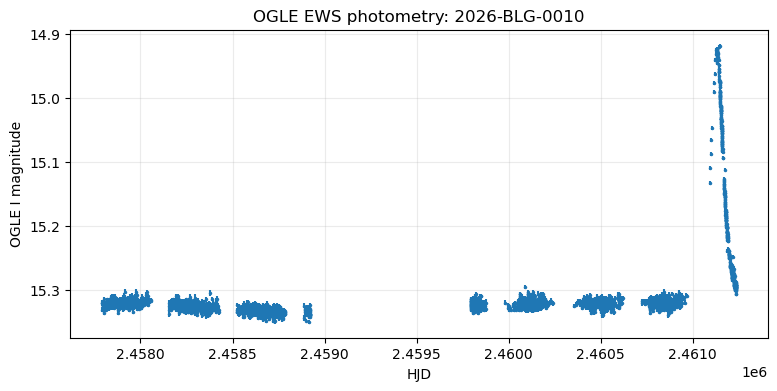

In [10]:
sample = filtered_events.head(1) if len(filtered_events) else events.head(1)
observations = EWS.photometry(sample, cache_dir=CACHE_DIR)
print(f'Observation rows: {len(observations):,}')
display(observations.head())

if len(observations):
    plt.figure(figsize=(9, 4))
    plt.errorbar(observations['epoch_hjd'], observations['magnitude'], yerr=observations['magnitude_err'], fmt='.', ms=3)
    plt.gca().invert_yaxis()
    plt.xlabel('HJD')
    plt.ylabel('OGLE I magnitude')
    plt.title(f'OGLE EWS photometry: {observations["target_id"].iloc[0]}')
    plt.grid(alpha=0.25)
    plt.show()

In [ ]:
# Proof of concept: photometry() downloads the linked whitespace-delimited phot.dat file.
photometry_url = str(sample.iloc[0]['photometry_url'])
phot_response = requests.get(photometry_url, timeout=60)
phot_response.raise_for_status()
raw_photometry = pd.read_csv(
    StringIO(phot_response.content.decode('latin-1')),
    sep=r'\s+', header=None,
    names=['epoch_hjd', 'magnitude', 'magnitude_err', 'seeing_arcsec', 'sky_background'],
)
print('Photometry URL:', photometry_url)
print(f'Raw phot.dat rows: {len(raw_photometry):,}')
display(raw_photometry.head())

## 5. Inspect provenance and cache

The target table keeps the event URL, photometry URL and archive URL. The downloaded text files are stored in the selected cache directory and can be reused in later runs.

In [11]:
display(sample[['target_id', 'event_url', 'photometry_url', 'archive_url', 'finding_chart_url']])
print(f"Cached files: {len(list(CACHE_DIR.glob('*.phot.dat')))} in {CACHE_DIR}")

,target_id,event_url,photometry_url,archive_url,finding_chart_url
9,2026-BLG-0010,https://ogle.astrouw.edu.pl/ogle4/ews/blg-0010...,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...,https://www.astrouw.edu.pl/ogle/ogle4/ews/2026...


Cached files: 1 in outputs/cache/ogle_photometry
